# Regressão Logística e SVM: guia passo a passo, começando do zero

Este é um **caderno de estudo**, para ler com calma e executar um pedacinho por vez.
Você não precisa entender todas as fórmulas antes de começar. Vamos olhar o dado,
entender o que queremos prever e ligar cada comando à ideia que ele implementa.

O guia acompanha **todo o código** de `trabalho_3_parte_3_regressao_logistica_svm.py`,
na versão do notebook resolvido que estava no projeto quando este material foi criado.
Os blocos grandes foram divididos em trechos menores, mantendo os comandos na ordem.
Há também exemplos extras, identificados como **experimentos didáticos**.

**Material de apoio:** *Uni_2.2.4_Classificação_Regressão Logística e SVM.pdf*,
da Prof.ª Dr.ª Andreza Sartori. As referências indicam a **página do arquivo PDF,
contada a partir de 1**. O PDF tem 59 páginas. As explicações aqui são paráfrases
e exemplos próprios relacionados a esse material.

**Como usar no VS Code:** abra este arquivo, selecione o kernel `.venv` com as
dependências do projeto e execute com `Shift+Enter`, de cima para baixo.
Se reiniciar o kernel, execute novamente as células anteriores: as variáveis
ficam na memória, e uma célula depende das anteriores.
Você pode usar “Executar tudo” para conferir os resultados e depois voltar à leitura.
O notebook não precisa abrir o PDF nem acessar a internet para executar.

**O que será criado ao executar:** o CSV e a imagem desta versão de estudo ficam
em `Parte-3/resultados_guia/`. Os arquivos da solução original ficam preservados.

## Roteiro de leitura

1. [Vocabulário e Python básico](#base): o significado de X, y, treino, teste e `fit`.
2. [Preparação dos dados](#preparo): arquivos, tabelas, Encoder e filtros.
3. [Regressão Logística](#logistica): pesos, sigmoide, probabilidade e classe.
4. [Credit Data e avaliação](#metricas): treino/teste, acurácia, precisão e recall.
5. [SVM](#svm): fronteira, margem e vetores de suporte.
6. [Kernels e validação](#validacao): como comparar configurações.
7. [GridSearch](#grade): a busca automática e a leitura das tabelas.
8. [Comparação e revisão](#revisao): o que os resultados permitem concluir.

**Sugestão:** na primeira leitura, vá até as duas previsões da base pequena.
Depois estude as métricas. Por último, avance para o SVM e a busca de parâmetros.

<a id="base"></a>
## 1. Antes do código: o que estamos tentando fazer?

Imagine uma tabela em que cada linha representa um cliente. Algumas colunas contam
coisas sobre ele. Outra coluna guarda uma resposta já conhecida: seu risco de crédito.
Queremos usar os exemplos conhecidos para aprender uma regra e aplicá-la a novos casos.

Isso é **aprendizado supervisionado**: durante o treino, entregamos as características
e as respostas corretas. É **classificação**, porque a resposta pertence a categorias.
No nosso exemplo, queremos uma classe como `alto` ou `baixo`, e não um valor em reais.
Apesar do nome “Regressão Logística”, seu uso aqui é de classificação.

**No PDF:** páginas 6–8 apresentam aprendizado supervisionado, classificação e regressão.

| Palavra no código | Tradução para este projeto |
|---|---|
| Registro, exemplo ou amostra | Uma linha: um cliente |
| Atributo ou feature | Uma informação de entrada, como renda |
| `X` | A tabela de informações que o modelo pode consultar |
| `y` | A resposta correta de cada linha |
| Modelo | A regra matemática aprendida a partir dos exemplos |
| Treinamento, `fit(X, y)` | Aprender a regra usando as entradas e suas respostas |
| Previsão, `predict(X)` | Aplicar a regra às entradas e devolver classes |
| Probabilidade, `predict_proba(X)` | Estimar a probabilidade das classes, quando disponível |
| Parâmetro aprendido | Um valor que o treino descobre, como um coeficiente |
| Hiperparâmetro | Uma escolha de configuração, como kernel ou C |

**Uma analogia:** no treino, você estuda exercícios com gabarito. No teste, responde
exercícios que não foram usados para aprender. Comparar com o gabarito do teste
é uma forma de avaliar se aprendeu um padrão que funciona em novos exemplos.

O método não “entende” um cliente como uma pessoa entende. Ele encontra padrões
nos números que recebe. Por isso precisamos cuidar da representação e da avaliação.

### Um pequeno dicionário de Python para acompanhar as próximas células

| Escrita | Como ler |
|---|---|
| `nome = valor` | Guarde esse valor com esse nome; `=` não é uma comparação |
| `a == b` / `a != b` | Pergunte se são iguais / diferentes |
| `funcao(...)` | Execute uma tarefa; dentro dos parênteses ficam os argumentos |
| `objeto.metodo(...)` | Execute uma tarefa oferecida por esse objeto |
| `objeto.atributo` | Consulte uma informação guardada no objeto |
| `[a, b, c]` | Uma lista em determinada ordem |
| `{'nome': valor}` | Um dicionário: associa uma chave a um valor |
| `dados[0]` | Pegue a primeira posição; Python começa a contar em zero |
| `dados[:, 1]` | Pegue todas as linhas e a segunda coluna de uma matriz |
| `for item in itens:` | Repita as linhas indentadas para cada item |
| `if condicao:` | Execute as linhas indentadas se a condição for verdadeira |
| `def tarefa(...):` | Defina uma tarefa reutilizável, chamada função |
| `# texto` | Comentário para quem lê; não executa uma operação |

A indentação, isto é, os espaços no começo da linha, define quais linhas pertencem
a um `for`, `if`, `with` ou função. Não é só uma escolha visual.

O final `_` em `coef_`, `classes_` ou `intercept_` segue a convenção do scikit-learn
para informações obtidas durante o ajuste. Já o final `_` de uma variável comum
não tem, por si só, um efeito mágico no Python.

### 1.1 — Buscar ferramentas nas bibliotecas

`import` disponibiliza ferramentas que outras pessoas já implementaram.
`as` dá um apelido curto: escrevemos `np.array` em vez de `numpy.array`.
`from ... import ...` traz uma ferramenta específica.

| Biblioteca | Para que aparece aqui |
|---|---|
| `Path` de `pathlib` | Encontrar arquivos e montar caminhos |
| `pickle` | Ler os dados que as partes anteriores salvaram em `.pkl` |
| `sys` | Consultar a versão do Python |
| `matplotlib` / `plt` | Desenhar gráficos |
| `numpy` / `np` | Trabalhar com vetores, matrizes e operações matemáticas |
| `pandas` / `pd` | Trabalhar com tabelas com nomes de colunas |
| `sklearn` | Biblioteca que oferece os algoritmos de aprendizado |
| `display` | Exibir uma tabela formatada no notebook |

O `if '__file__' in globals()` verifica se existe a variável que informa o caminho
de um script `.py`. No notebook ela normalmente não existe. No script, ativamos
o backend `Agg`, que desenha e salva imagens sem abrir uma janela.
`globals()` é o dicionário de nomes disponíveis no ambiente atual.

In [1]:
from pathlib import Path
import pickle
import sys

import matplotlib

if '__file__' in globals():
    matplotlib.use('Agg')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display

### 1.2 — Importar os modelos e as ferramentas de avaliação

Os nomes terminados em `Classifier` são classificadores. `LogisticRegression`
também é um classificador neste uso. `SVC` significa classificação com vetores de suporte.
Importar uma classe ainda não treina modelo algum.

As ferramentas têm três papéis:

- **Aprender:** `LogisticRegression`, `SVC`, `GaussianNB` e `RandomForestClassifier`.
- **Preparar e escolher configurações:** `LabelEncoder`, `StratifiedKFold`,
  `cross_val_score` e `GridSearchCV`.
- **Avaliar:** `accuracy_score`, `precision_score`, `recall_score`, `f1_score`,
  `confusion_matrix`, `classification_report` e `ConfusionMatrixDisplay`.

As que terminam em `_score` calculam números. `confusion_matrix` conta tipos de
acertos e erros. `ConfusionMatrixDisplay` desenha essa contagem.
`classification_report` reúne várias métricas em um relatório.

In [2]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, classification_report,
    confusion_matrix, precision_score, recall_score, f1_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC

### 1.3 — Descobrir onde estão as bases

Este trecho cuida da organização dos arquivos; ele não faz aprendizado.
Você pode voltar a ele depois sem perder a ideia dos algoritmos.

1. `Path.cwd()` consulta a pasta de trabalho atual do notebook.
   No `.py`, `Path(__file__).resolve().parent` encontra a pasta do próprio script.
   `resolve()` transforma em caminho absoluto e `.parent` pega a pasta que contém o arquivo.
2. A expressão `A if condicao else B` escolhe A ou B.
3. `[inicio, *inicio.parents]` reúne a pasta inicial e as pastas acima dela.
   O `*` coloca os elementos de `inicio.parents` dentro da lista.
4. O `for` procura os dois arquivos esperados em cada candidata.
   `p / 'Parte-1/risco_credito.pkl'` monta um caminho; aqui `/` não é divisão.
5. `is_file()` pergunta se existe um arquivo naquele caminho. `and` exige as duas condições.
6. `next((... for ... if ...), None)` pega a primeira candidata válida;
   se nenhuma servir, devolve `None`, que representa ausência de valor.
7. `break` encerra a busca assim que encontra a pasta.
8. O `else` deste `for` roda se o laço terminar sem `break`. `raise` então mostra um erro útil.

`pasta_projeto` será a pasta `fase3-TrabalhoIA`. `pasta_saida` indica onde salvar resultados.

In [3]:
inicio = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
for ancestral in [inicio, *inicio.parents]:
    candidatos = [ancestral, ancestral / 'fase3-TrabalhoIA']
    pasta_projeto = next((p for p in candidatos if
        (p / 'Parte-1/risco_credito.pkl').is_file() and
        (p / 'Parte-2/credit.pkl').is_file()), None)
    if pasta_projeto is not None:
        break
else:
    raise FileNotFoundError('Não foi encontrada a pasta fase3-TrabalhoIA com as bases das partes 1 e 2.')

pasta_saida = pasta_projeto / 'Parte-3'

**Adaptação só para este guia:** abaixo mudamos a pasta de saída para
`Parte-3/resultados_guia`. Assim, ao estudar e executar novamente, os gráficos e
o CSV desta versão têm seu próprio lugar. `mkdir` cria a pasta;
`exist_ok=True` permite que ela já exista e `parents=True` permite criar os pais necessários.

In [4]:
pasta_saida = pasta_projeto / 'Parte-3' / 'resultados_guia'
pasta_saida.mkdir(parents=True, exist_ok=True)

### 1.4 — Mostrar versões para conseguir repetir o trabalho

`print` escreve texto na saída. Podemos passar vários itens, separados por vírgulas.
`sys.version.split()[0]` quebra o texto da versão em pedaços e pega o primeiro.
`__version__` é a informação de versão fornecida pelas bibliotecas.

Por que mostrar isso? Os algoritmos fazem cálculos numéricos. Uma versão diferente
pode parar a otimização em um ponto ligeiramente diferente e mudar as últimas casas
dos coeficientes. Registrar o ambiente ajuda a investigar essas diferenças.

Este projeto usa pandas 3 ou superior para conseguir ler a estrutura de texto
guardada no Pickle fornecido. Use as dependências de `fase3-TrabalhoIA/requirements.txt`.

In [5]:
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Pasta do projeto:', pasta_projeto)

Python: 3.13.6
NumPy: 2.5.3 | pandas: 3.1.1 | scikit-learn: 1.9.1
Pasta do projeto: C:\programas\IA_Aplicada\fase3-TrabalhoIA


<a id="preparo"></a>
## 2. Preparar a base pequena: de uma tabela a números

A base da Parte 1 tem **14 clientes**, quatro informações de entrada e a coluna `risco`.
A Parte 1 já transformou as palavras das entradas em números e salvou o resultado.
Agora vamos recuperar esse trabalho e conferir o significado de cada código.

**Ligação com o PDF:** páginas 16 e 23 mostram a base com Encoder e o uso apenas
das classes `baixo` e `alto`. Retirar `moderado` é uma simplificação deste exercício,
não uma regra que torne a Regressão Logística incapaz de tratar múltiplas classes.

### 2.1 — Abrir risco_credito.pkl

`with ... as arquivo` abre um recurso e garante seu fechamento ao sair do bloco.
`open('rb')` abre em modo **leitura binária**: `r` vem de read e `b`, de binary.
Pickle guarda objetos Python; não é um CSV de texto.

`pickle.load(arquivo)` recupera os objetos. O arquivo contém dois elementos.
A escrita `X_risco_credito, y_risco_credito = ...` os distribui entre dois nomes,
na mesma ordem em que foram salvos.

- `X_risco_credito`: os quatro atributos de cada cliente.
- `y_risco_credito`: a resposta conhecida de cada cliente.

Aqui carregamos os arquivos do próprio projeto. Como Pickle pode executar operações
ao desserializar, não use esse comando para arquivos de origem desconhecida.

In [6]:
with (pasta_projeto / 'Parte-1/risco_credito.pkl').open('rb') as arquivo:
    X_risco_credito, y_risco_credito = pickle.load(arquivo)

### 2.2 — Organizar os tipos e ler o CSV original

`np.asarray` transforma os dados em arrays do NumPy: estruturas organizadas de números
ou textos. `dtype=int` pede números inteiros e `dtype=str` pede texto.
Isso evita depender do tipo específico usado quando o arquivo foi criado.

`pd.read_csv` lê o arquivo original como um `DataFrame`: uma tabela com nomes de colunas.
Ele será usado para recuperar os codificadores e verificar o Pickle.
`atributos_risco` guarda uma lista na ordem correta das quatro colunas de X.

**A ordem é parte do significado:** `[historia, divida, garantias, renda]`.
Se trocarmos renda e história, o algoritmo recebe números válidos com sentidos errados.

In [7]:
X_risco_credito = np.asarray(X_risco_credito, dtype=int)
y_risco_credito = np.asarray(y_risco_credito, dtype=str)
dataset_risco_credito = pd.read_csv(pasta_projeto / 'Parte-1/risco_credito.csv')
atributos_risco = ['historia', 'divida', 'garantias', 'renda']

**Experimento didático — olhar antes de calcular:** `head()` mostra as primeiras
linhas, `.shape` mostra o formato e `[0]` pega a primeira linha de X.
O primeiro registro deve corresponder à primeira resposta de y.

In [8]:
display(dataset_risco_credito.head())
print('Formato de X:', X_risco_credito.shape)
print('Formato de y:', y_risco_credito.shape)
print('Primeiro cliente codificado:', X_risco_credito[0])
print('Risco desse mesmo cliente:', y_risco_credito[0])

,historia,divida,garantias,renda,risco
0,ruim,alta,nenhuma,0_15,alto
1,desconhecida,alta,nenhuma,15_35,alto
2,desconhecida,baixa,nenhuma,15_35,moderado
3,desconhecida,baixa,nenhuma,acima_35,alto
4,desconhecida,baixa,nenhuma,acima_35,baixo


Formato de X: (14, 4)
Formato de y: (14,)
Primeiro cliente codificado: [2 0 1 0]
Risco desse mesmo cliente: alto


**Como ler `(14, 4)` e `(14,)`:** X tem 14 linhas e quatro colunas.
y é uma sequência de 14 respostas; a vírgula em `(14,)` faz parte da notação
de uma tupla com um elemento. Não significa que uma informação foi esquecida.

**Pense antes de continuar:** colocar a coluna `risco` dentro de X daria ao modelo
o próprio gabarito como entrada. A avaliação deixaria de representar a tarefa de
prever o risco quando ele ainda é desconhecido.

### 2.3 — Criar um dicionário de códigos para cada coluna

Um `LabelEncoder` funciona como um dicionário de tradução, por exemplo,
`boa → 0`, `desconhecida → 1`, `ruim → 2`.

| Comando | O que faz |
|---|---|
| `encoders = {}` | Cria um dicionário vazio para guardar cada tradutor |
| `np.empty_like(X)` | Reserva uma matriz com o formato e tipo de X |
| `enumerate(atributos_risco)` | Entrega a posição `i` e o nome `atributo` em cada volta |
| `LabelEncoder()` | Cria um novo tradutor |
| `fit_transform(coluna)` | Aprende os códigos dessa coluna e aplica a tradução |
| `X_conferencia[:, i]` | Todas as linhas da coluna de posição `i` |
| `encoders[atributo] = encoder` | Guarda o tradutor com o nome da coluna |

`empty_like` não inicia com dados úteis: o laço deve preencher todas as colunas,
como faz aqui. Precisamos de um Encoder por coluna para preservar seus mapeamentos.

A última linha apenas formata a impressão: `encoder.classes_` lista as categorias;
`transform` obtém os códigos; `map(int, ...)` os converte em inteiros Python;
`zip` junta categoria e código em pares; `dict` transforma os pares em um dicionário.

In [9]:
encoders = {}
X_conferencia = np.empty_like(X_risco_credito)
for i, atributo in enumerate(atributos_risco):
    encoder = LabelEncoder()
    X_conferencia[:, i] = encoder.fit_transform(dataset_risco_credito[atributo])
    encoders[atributo] = encoder
    print(atributo, dict(zip(encoder.classes_, map(int, encoder.transform(encoder.classes_)))))

historia {'boa': 0, 'desconhecida': 1, 'ruim': 2}
divida {'alta': 0, 'baixa': 1}
garantias {'adequada': 0, 'nenhuma': 1}
renda {'0_15': 0, '15_35': 1, 'acima_35': 2}


**Um cuidado conceitual:** história `ruim = 2` não significa “duas vezes boa”.
Os números são rótulos. Mantemos essa representação para reproduzir a atividade.
Em outro projeto, categorias sem ordem podem pedir uma representação como
one-hot encoding. O Encoder não descobre qualidade, risco ou causalidade.

### 2.4 — Conferir se CSV e Pickle descrevem a mesma base

`np.testing.assert_array_equal(a, b)` verifica se os arrays têm o mesmo formato
e os mesmos valores. Se estiverem diferentes, interrompe a execução com um erro.
Se estiverem iguais, normalmente não imprime nada.

A primeira conferência compara as entradas codificadas. A segunda compara o gabarito.
`dataset['risco']` seleciona a coluna pelo nome; `.to_numpy(dtype=str)` a coloca
em formato NumPy de texto.

Isso é uma checagem de consistência dos arquivos, não uma avaliação da qualidade do modelo.

In [10]:
np.testing.assert_array_equal(X_conferencia, X_risco_credito)
np.testing.assert_array_equal(dataset_risco_credito['risco'].to_numpy(dtype=str), y_risco_credito)

### 2.5 — Remover moderado sem separar o cliente de sua resposta

`y_risco_credito != 'moderado'` faz a comparação em cada posição de y e produz
uma **máscara booleana**: uma sequência de `True` e `False`.
`True` significa “guardar”; `False`, “deixar de fora”.

Aplicamos a **mesma máscara** a X e a y. Assim, removemos a linha e sua resposta juntas.
Depois criamos outro Encoder, desta vez para a saída: `alto = 0`, `baixo = 1`.
`fit_transform` aprende esses dois nomes e devolve os códigos.

`assert ... and ...` exige que a base original tenha `(14, 4)` e a filtrada `(11, 4)`.
Se isso for falso, o Python para aqui. Ter 11 linhas é a consequência de excluir
os três casos de risco moderado, não um resultado de aprendizagem.

In [11]:
mascara_binaria = y_risco_credito != 'moderado'
X_risco_binario = X_risco_credito[mascara_binaria]
encoder_classe = LabelEncoder()
y_risco_binario = encoder_classe.fit_transform(y_risco_credito[mascara_binaria])
assert X_risco_credito.shape == (14, 4) and X_risco_binario.shape == (11, 4)

**Experimento didático — enxergar a máscara:** a linha que some de X é exatamente
aquela cuja resposta é `moderado`. Não estamos apagando posições à mão.

In [12]:
display(pd.DataFrame({
    'risco_original': y_risco_credito,
    'manter_linha': mascara_binaria,
}))
print('Linhas mantidas:', mascara_binaria.sum())
print('Linhas removidas:', (~mascara_binaria).sum())

,risco_original,manter_linha
0,alto,True
1,alto,True
2,moderado,False
3,alto,True
4,baixo,True
5,baixo,True
6,alto,True
7,moderado,False
8,baixo,True
9,baixo,True


Linhas mantidas: 11
Linhas removidas: 3


### 2.6 — Voltar dos números às palavras para conferir a tabela

`inverse_transform` faz a tradução no sentido inverso: `0 → alto`, `1 → baixo`.
Criamos uma tabela com as entradas e adicionamos a coluna `risco` para inspecioná-la.
Essa tabela é só para visualização; o treinamento continuará usando X e y separados.

`value_counts()` conta quantas vezes cada resposta aparece.
`to_frame('quantidade')` transforma a contagem em uma tabela de uma coluna com esse nome.
Você deve ver seis casos `alto` e cinco `baixo`.

**Guarde esta associação:** neste modelo pequeno, a classe positiva, de código 1,
será `baixo`. “Positiva” significa apenas a classe de referência do cálculo;
não quer dizer que a situação seja boa ou ruim por natureza.

In [13]:
print('Classes binárias:', dict(zip(encoder_classe.classes_, map(int, encoder_classe.transform(encoder_classe.classes_)))))
dados_binarios = pd.DataFrame(X_risco_binario, columns=atributos_risco)
dados_binarios['risco'] = encoder_classe.inverse_transform(y_risco_binario)
display(dados_binarios)
display(dados_binarios['risco'].value_counts().to_frame('quantidade'))

Classes binárias: {np.str_('alto'): 0, np.str_('baixo'): 1}


,historia,divida,garantias,renda,risco
0,2,0,1,0,alto
1,1,0,1,1,alto
2,1,1,1,2,alto
3,1,1,1,2,baixo
4,1,1,0,2,baixo
5,2,1,1,0,alto
6,0,1,1,2,baixo
7,0,0,0,2,baixo
8,0,0,1,0,alto
9,0,0,1,2,baixo


,quantidade
risco,
alto,6
baixo,5


<a id="logistica"></a>
## 3. Regressão Logística: da soma à probabilidade

Vamos construir a previsão em duas etapas:

1. Combinar os atributos com pesos aprendidos: uma soma chamada aqui de **z**.
2. Aplicar a **sigmoide**, que transforma z em uma probabilidade estimada entre 0 e 1.

$$z = B_0 + B_1 x_1 + B_2 x_2 + B_3 x_3 + B_4 x_4$$
$$p = \frac{1}{1+e^{-z}}$$

- Os x são as entradas do cliente. Os B são os valores aprendidos no treino.
- `B0` é o intercepto: o termo constante da soma.
- Cada outro B multiplica uma coluna de X.
- `e` é a constante matemática aproximada por 2,71828; `np.exp` calcula potências de e.
- Se z for zero, p será 0,5. z muito positivo leva p para perto de 1;
  z muito negativo leva p para perto de 0.

**No PDF:** páginas 9–15 apresentam a ideia de probabilidade e a sigmoide;
17–18, os pesos e a redução do custo; 19–22, a classificação e o limiar.

**Para não misturar símbolos:** o PDF usa y na equação da reta. Neste código,
chamamos essa soma de z, pois o nome `y` já representa o gabarito dos clientes.
É uma diferença de notação, não de ideia.

A relação `log(p / (1 - p)) = z` recebe o nome **logit**. Ela é a forma inversa da
sigmoide: não é uma terceira transformação que precisamos aplicar depois de obter p
para chamar `predict`. O modelo ajusta os pesos e depois usa soma e sigmoide na previsão.
Não há garantia de encaixar perfeitamente todos os dados.

### 3.1 — Criar o modelo e ensinar com fit

`LogisticRegression(...)` cria um objeto configurado, mas ainda sem pesos aprendidos.
`logistica_risco.fit(X_risco_binario, y_risco_binario)` aprende os pesos usando os
11 exemplos e suas classes. Guardamos o objeto em `logistica_risco` para usá-lo depois.

| Argumento | Significado neste código |
|---|---|
| `random_state=1` | Mantém a configuração solicitada pelo exercício |
| `solver='lbfgs'` | Escolhe o método numérico que procura pesos de menor custo |
| `C=1.0` | Define a força inversa da regularização; C menor contém mais os pesos |
| `max_iter=1000` | Limite de iterações, não uma ordem para executar exatamente mil |

O PDF mostra descida do gradiente como uma técnica de otimização. Aqui usamos
**L-BFGS**, outro método de otimização; não implementamos descida do gradiente à mão.
O custo penaliza previsões inadequadas e inclui regularização para controlar os pesos.

Precisão sobre `random_state`: com o solver `lbfgs`, esse argumento não controla
aleatoriedade; ele é relevante para outros solvers. Mantê-lo não é uma garantia
de valores idênticos entre versões de bibliotecas e computadores.

In [14]:
logistica_risco = LogisticRegression(random_state=1, solver='lbfgs', C=1.0, max_iter=1000)
logistica_risco.fit(X_risco_binario, y_risco_binario)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",1
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

### 3.2 — Ler os pesos que o modelo aprendeu

`intercept_` é uma informação do modelo treinado: o B0.
`coef_` contém os quatro pesos, na ordem dos atributos de X.
`classes_` informa quais classes o modelo conhece e em que ordem organiza as probabilidades.

Por que aparecem colchetes duplos em `coef_`? A biblioteca usa uma matriz para
acomodar diferentes situações. Na classificação binária há uma linha de coeficientes.

Para esta codificação, um coeficiente positivo aumenta z quando a entrada cresce,
mantendo as outras fixas. Isso aumenta a probabilidade de `baixo`, pois esse é o código 1.
Um coeficiente negativo faz o movimento oposto. Não interprete isso como causa:
são padrões do modelo, em uma base minúscula com categorias representadas por códigos.

In [15]:
print('B0 (intercept_):', logistica_risco.intercept_)
print('B1 a B4 (coef_):', logistica_risco.coef_)
print('Classes do modelo:', logistica_risco.classes_)

B0 (intercept_): [-0.80855152]
B1 a B4 (coef_): [[-0.76706797  0.23921064 -0.47989768  1.12196145]]
Classes do modelo: [0 1]


### 3.3 — Comparar o cálculo com as referências do exercício

`referencia` é um array com os cinco números citados no enunciado.
`coef_.ravel()` transforma a matriz de pesos em uma sequência de quatro números.
`np.r_[...]` junta o intercepto e os quatro pesos em uma única sequência.

Dentro do dicionário da tabela, `['B0', *atributos_risco]` combina o nome B0 com
os quatro nomes de atributos. `calculado - referencia` subtrai os arrays posição
por posição; `np.abs` tira o sinal de cada diferença.

Diferenças pequenas podem vir da otimização e da versão da biblioteca. Não
substituímos o resultado do treino pelos números de referência. Na execução
original do projeto, a maior diferença ficou abaixo de 0,0003 e as duas classes
previstas foram as esperadas.

In [16]:
referencia = np.array([-0.80828993, -0.76704533, 0.23906678, -0.47976059, 1.12186218])
calculado = np.r_[logistica_risco.intercept_, logistica_risco.coef_.ravel()]
display(pd.DataFrame({
    'parametro': ['B0', *atributos_risco],
    'referencia_enunciado': referencia,
    'calculado': calculado,
    'diferenca_absoluta': np.abs(calculado - referencia),
}))

,parametro,referencia_enunciado,calculado,diferenca_absoluta
0,B0,-0.808290,-0.808552,0.000262
1,historia,-0.767045,-0.767068,0.000023
2,divida,0.239067,0.239211,0.000144
3,garantias,-0.479761,-0.479898,0.000137
4,renda,1.121862,1.121961,0.000099


**Experimento didático — ver a sigmoide:** o eixo horizontal será a soma z;
o vertical, a probabilidade p. Ainda não estamos desenhando a Credit Data.
`linspace(-6, 6, 200)` cria 200 pontos entre -6 e 6. As operações do NumPy são
aplicadas a cada ponto. `subplots` cria a figura e seus eixos; `plot` desenha a curva.
As linhas de 0 e 0,5 ajudam a localizar o limiar.

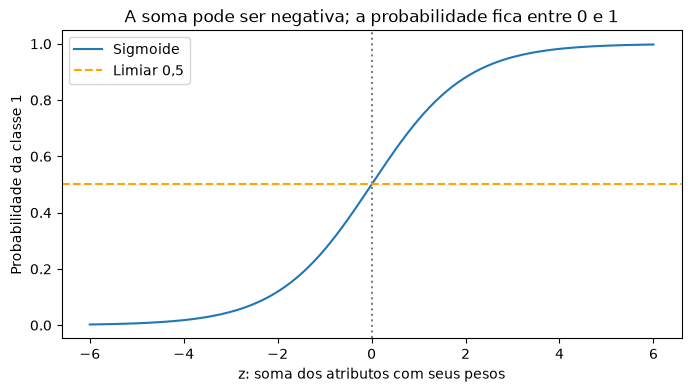

In [17]:
did_z = np.linspace(-6, 6, 200)
did_p = 1 / (1 + np.exp(-did_z))
did_fig, did_ax = plt.subplots(figsize=(8, 4))
did_ax.plot(did_z, did_p, label='Sigmoide')
did_ax.axvline(0, color='gray', linestyle=':')
did_ax.axhline(0.5, color='orange', linestyle='--', label='Limiar 0,5')
did_ax.set(xlabel='z: soma dos atributos com seus pesos', ylabel='Probabilidade da classe 1',
           title='A soma pode ser negativa; a probabilidade fica entre 0 e 1')
did_ax.legend()
plt.show()
plt.close(did_fig)

### 3.4 — Preparar os dois clientes para a previsão

`clientes_texto` é uma tabela com duas linhas, uma para cada cliente do enunciado.
`columns=atributos_risco` garante os nomes e a ordem das colunas.

A expressão `[encoders[atributo].transform(...) for atributo in atributos_risco]`
é uma **compreensão de lista**: repete a transformação para cada atributo e guarda
os resultados. Ela equivale a percorrer as colunas com um `for`.
`np.column_stack` coloca as quatro sequências lado a lado e produz uma matriz 2×4.

Aqui usamos **transform**, sem `fit`: os tradutores já aprenderam os códigos.
Aprender outro mapeamento só com esses clientes poderia alterar o significado dos números.
As linhas resultantes são `[0, 0, 1, 2]` e `[2, 0, 0, 0]`.

In [18]:
clientes_texto = pd.DataFrame([
    ['boa', 'alta', 'nenhuma', 'acima_35'],
    ['ruim', 'alta', 'adequada', '0_15'],
], columns=atributos_risco)
novos_clientes = np.column_stack([
    encoders[atributo].transform(clientes_texto[atributo]) for atributo in atributos_risco
])

### 3.5 — Pedir a classe, a probabilidade e conferir a resposta

`predict(novos_clientes)` aplica a regra aprendida e devolve códigos de classe.
`inverse_transform(...)` os traduz para `baixo` e `alto`.
`.copy()` cria uma cópia da tabela para acrescentarmos os resultados.

`predict_proba` devolve uma matriz: uma linha por cliente e uma coluna por classe,
na ordem de `logistica_risco.classes_`. `[:, 1]` seleciona a **segunda coluna**,
que neste caso é o código 1, `baixo`. Não é uma garantia de que “a segunda coluna
sempre representa um bom cliente” em qualquer conjunto de dados.

O modelo compara as duas classes. No caso binário usual, z positivo, equivalente
a p maior que 0,5, leva à classe 1; p abaixo de 0,5 leva à classe 0.
No empate exato z=0, este `predict` binário escolhe a classe 0.
Não é necessário implementar o limiar para usar `predict`.

O `assert_array_equal` final confere as classes esperadas. Ele não altera as previsões
para forçar um resultado. São probabilidades estimadas pelo modelo, não garantias
de comportamento de uma pessoa.

In [19]:
previsoes_clientes = encoder_classe.inverse_transform(logistica_risco.predict(novos_clientes))
resultado_clientes = clientes_texto.copy()
resultado_clientes['previsao'] = previsoes_clientes
resultado_clientes['P(baixo)'] = logistica_risco.predict_proba(novos_clientes)[:, 1]
display(resultado_clientes)
np.testing.assert_array_equal(previsoes_clientes, ['baixo', 'alto'])

,historia,divida,garantias,renda,previsao,P(baixo)
0,boa,alta,nenhuma,acima_35,baixo,0.722215
1,ruim,alta,adequada,0_15,alto,0.087649


### Experimento didático — calcular a previsão do primeiro cliente na mão

Agora vamos ligar os B à tabela de probabilidade. O cliente tem entradas `[0, 0, 1, 2]`.
O zero de uma categoria é um código, não a ausência física de uma característica.

1. Pegamos a primeira linha de X com `[0]`.
2. Pegamos a única linha de pesos com `coef_[0]`.
3. `entradas * pesos` multiplica posição por posição.
4. `.sum()` soma essas contribuições e adicionamos B0.
5. `np.exp(-z)` entra na sigmoide.

A soma fica perto de **0,96** e a probabilidade de `baixo`, perto de **72,2%**.
`np.isclose` verifica se duas contas são suficientemente próximas, permitindo
pequenas diferenças de arredondamento do computador.

In [20]:
did_entradas = novos_clientes[0]
did_pesos = logistica_risco.coef_[0]
did_contribuicoes = did_entradas * did_pesos
display(pd.DataFrame({
    'atributo': atributos_risco,
    'entrada': did_entradas,
    'peso_aprendido': did_pesos,
    'entrada_vezes_peso': did_contribuicoes,
}))
did_soma = logistica_risco.intercept_[0] + did_contribuicoes.sum()
did_probabilidade = 1 / (1 + np.exp(-did_soma))
print('Soma z:', did_soma)
print('Probabilidade de baixo:', did_probabilidade)
print('Probabilidade pela biblioteca:', logistica_risco.predict_proba(novos_clientes)[0, 1])
assert np.isclose(did_probabilidade, logistica_risco.predict_proba(novos_clientes)[0, 1])

,atributo,entrada,peso_aprendido,entrada_vezes_peso
0,historia,0,-0.767068,-0.000000
1,divida,0,0.239211,0.000000
2,garantias,1,-0.479898,-0.479898
3,renda,2,1.121961,2.243923


Soma z: 0.9554737012321024
Probabilidade de baixo: 0.722214650101006
Probabilidade pela biblioteca: 0.722214650101006


**Confira se entendeu:** por que p=0,72 leva a `baixo` aqui?

**Resposta:** porque o Encoder definiu `baixo` como classe 1, e 0,72 é a
probabilidade estimada dessa classe. Não existe uma regra universal que associe
o número 1 a risco alto ou baixo. Essa definição vem dos dados e da codificação.

<a id="metricas"></a>
## 4. Base maior: aprender com o treino e avaliar no teste

Agora mudamos de conjunto de dados. A Credit Data tem três atributos:
`income` (renda), `age` (idade) e `loan` (valor do empréstimo).
Ela vem separada em 1.500 exemplos de treino e 500 de teste.

**Atenção: o significado de y mudou.**

| Onde estamos | Código 0 | Código 1 |
|---|---|---|
| Risco de crédito com 11 exemplos | alto | baixo |
| Credit Data | paga | não paga |
| Exemplo de pagamento no PDF, páginas 9–14 | não paga | paga |

O sentido de uma probabilidade ou de um erro depende dessa tabela. O gráfico
do PDF explica a ideia matemática, mas a associação entre os números e as classes
não precisa ser a mesma do arquivo Credit Data.

**No PDF:** páginas 51–54 apresentam avaliação por divisão dos dados e K-fold.
A divisão única entre treino e teste é chamada de **holdout**. As proporções
usadas em aula são exemplos, não uma obrigação: neste arquivo são 75% e 25%.

### 4.1 — Recuperar quatro objetos e garantir a divisão original

Este Pickle guarda quatro elementos, na ordem usada pela Parte 2:
X de treino, y de treino, X de teste, y de teste. A atribuição os recupera nessa ordem.
As conversões com `asarray` pedem números reais (`float`) para entradas e inteiros para classes.
O `assert` e os `print` conferem as dimensões esperadas.

**O que vai para fit?** Só `X_credit_treinamento` e `y_credit_treinamento`.
**O que vai para predict na avaliação?** `X_credit_teste`.
**Quando usamos y de teste?** Depois de prever, para comparar com o gabarito.
Não passamos y de teste ao treinamento.

As entradas já estão em escala padronizada no arquivo. Padronizar é colocar
medidas de escalas diferentes em uma escala comparável. Não é traduzir palavras
com um Encoder. Um valor padronizado negativo não significa renda negativa.

In [21]:
with (pasta_projeto / 'Parte-2/credit.pkl').open('rb') as arquivo:
    X_credit_treinamento, y_credit_treinamento, X_credit_teste, y_credit_teste = pickle.load(arquivo)

X_credit_treinamento = np.asarray(X_credit_treinamento, dtype=float)
X_credit_teste = np.asarray(X_credit_teste, dtype=float)
y_credit_treinamento = np.asarray(y_credit_treinamento, dtype=int)
y_credit_teste = np.asarray(y_credit_teste, dtype=int)
assert X_credit_treinamento.shape == (1500, 3) and X_credit_teste.shape == (500, 3)
print('X treino:', X_credit_treinamento.shape, '| y treino:', y_credit_treinamento.shape)
print('X teste:', X_credit_teste.shape, '| y teste:', y_credit_teste.shape)

X treino: (1500, 3) | y treino: (1500,)
X teste: (500, 3) | y teste: (500,)


### 4.2 — Ver as escalas e contar as classes do teste

`mean(axis=0)` calcula uma média para cada coluna; `std(axis=0)`, um desvio padrão.
`axis=0` aqui combina as linhas e preserva uma medida por atributo.
A tabela ajuda a observar que as entradas estão próximas da escala de média zero
e desvio um. A média do treino não precisa ser exatamente zero para um arquivo
que já veio pré-processado e dividido.

`pd.Series(y)` cria uma coluna com o gabarito. `value_counts()` conta as classes;
`sort_index()` põe os códigos em ordem; `rename_axis('classe')` nomeia o índice.
`to_frame` dá o formato de tabela.

No teste temos **436 pagantes e 64 não pagantes**. As classes são desbalanceadas:
há muito mais exemplos de uma classe. Um modelo que respondesse “paga” sempre
já teria 436/500 = **87,2%** de acurácia e encontraria **zero** não pagantes.

O código que criou `credit.pkl` não acompanha o projeto. Não conseguimos garantir
que a padronização original foi ajustada somente no treino. Ao preparar os dados
brutos, o scaler deve aprender só com o treino e, na validação, dentro de cada dobra.

In [22]:
display(pd.DataFrame({
    'atributo': ['income', 'age', 'loan'],
    'media_treino': X_credit_treinamento.mean(axis=0),
    'desvio_treino': X_credit_treinamento.std(axis=0),
}))
print('Distribuição das classes no teste:')
display(pd.Series(y_credit_teste).value_counts().sort_index().rename_axis('classe').to_frame('quantidade'))

,atributo,media_treino,desvio_treino
0,income,0.012726,0.998850
1,age,-0.002513,0.991328
2,loan,0.014762,0.999907


Distribuição das classes no teste:


,quantidade
classe,
0,436
1,64


### 4.3 — Entender os quatro quadradinhos da matriz de confusão

Uma matriz de confusão é uma tabela de contagens. Fixamos `labels=[0, 1]` para
ter a ordem conhecida. As **linhas são a realidade**; as **colunas são a previsão**.

| Realidade / previsão | Paga (0) | Não paga (1) |
|---|---|---|
| Paga (0) | VN: acertou um pagante | FP: acusou um pagante de não pagar |
| Não paga (1) | FN: deixou passar um não pagante | VP: encontrou um não pagante |

V = verdadeiro, F = falso, P = positivo (classe 1), N = negativo (classe 0).
**Falso negativo aqui:** o modelo diz “paga”, mas a resposta real é “não paga”.

| Métrica | Pergunta | Conta para a classe 1 |
|---|---|---|
| Acurácia | Quantas respostas acertou no total? | (VN + VP) / total |
| Precisão | Dos previstos como não pagantes, quantos eram mesmo? | VP / (VP + FP) |
| Recall, ou sensibilidade | Dos não pagantes reais, quantos encontrou? | VP / (VP + FN) |
| F1 | Como equilibrar precisão e recall em um número? | 2 × precisão × recall / (precisão + recall) |

“Taxa de acerto” costuma indicar acurácia. A coluna `precision` do relatório é
**precisão**, uma métrica diferente. Um modelo pode melhorar uma e piorar a outra.

### 4.4 — Definir uma função para calcular as métricas

`def metricas_modelo(nome, previsoes):` cria uma função reutilizável.
Definir a função ainda não calcula os resultados; é preciso chamá-la depois.
Ela recebe um nome e as previsões e usa `y_credit_teste`, que já está no ambiente.
Isso significa que essa função foi feita para este teste específico.

`confusion_matrix(...).ravel()` transforma a matriz 2×2 em quatro posições,
na ordem `[VN, FP, FN, VP]`. A atribuição distribui os valores em quatro nomes.
`return` entrega um dicionário com as métricas para quem chamou a função.

As funções de precisão, recall e F1 usam a classe 1 como positiva por padrão.
`zero_division=0` faz o resultado ser zero quando uma dessas razões não pode ser
calculada por falta de exemplos previstos/reais; isso não transforma um modelo
ruim em bom. `int` transforma contagens em inteiros Python para apresentação.

In [23]:
def metricas_modelo(nome, previsoes):
    vn, fp, fn, vp = confusion_matrix(y_credit_teste, previsoes, labels=[0, 1]).ravel()
    return {
        'modelo': nome, 'acuracia': accuracy_score(y_credit_teste, previsoes),
        'precisao_1': precision_score(y_credit_teste, previsoes, zero_division=0),
        'recall_1': recall_score(y_credit_teste, previsoes, zero_division=0),
        'f1_1': f1_score(y_credit_teste, previsoes, zero_division=0),
        'VN': int(vn), 'FP': int(fp), 'FN': int(fn), 'VP': int(vp),
    }

### 4.5 — Definir uma função para escrever o relatório

Esta segunda função chama a primeira e imprime os resultados de forma legível.
`medidas['acuracia']` consulta o valor de uma chave do dicionário.
Uma f-string começa com `f` e coloca valores nos pontos marcados por `{...}`.

- `:.4f` mostra um número com quatro casas: 0.9460.
- `:.2%` mostra o mesmo valor como porcentagem com duas casas: 94.60%.
- `target_names` fornece os nomes das classes do relatório, na ordem de `labels`.
- `digits=4` muda as casas mostradas, não os resultados internos.

No `classification_report`, cada linha de classe tem sua própria precisão e recall.
`support` é a quantidade de exemplos reais dessa classe; `macro avg` é a média
simples entre classes; `weighted avg` pondera pela quantidade de exemplos de cada uma.

A função imprime uma saída, mas não tem `return` explícito. Seu objetivo é comunicar;
quem precisa dos números organizados chama `metricas_modelo`.

In [24]:
def relatorio_modelo(nome, previsoes):
    medidas = metricas_modelo(nome, previsoes)
    print(f"{nome}: acurácia = {medidas['acuracia']:.4f} ({medidas['acuracia']:.2%})")
    print('Matriz [[VN, FP], [FN, VP]]:')
    print(confusion_matrix(y_credit_teste, previsoes, labels=[0, 1]))
    print(f"Não pagantes encontrados: {medidas['VP']}; não pagantes previstos como pagantes: {medidas['FN']}.")
    print(classification_report(y_credit_teste, previsoes, labels=[0, 1],
        target_names=['Paga (0)', 'Não paga (1)'], digits=4, zero_division=0))

### 4.6 — Treinar outro modelo logístico e medir a taxa de acerto

Criamos `logistica_credit`, um objeto diferente de `logistica_risco`.
O primeiro tem três entradas da Credit Data; o segundo tem quatro entradas da base pequena.
Usar nomes diferentes evita misturar modelos e significados de classes.

O fluxo continua igual: criar → `fit` com treino → `predict` com teste → comparar.
`head(20)` mostra só as primeiras 20 linhas para inspeção. As métricas usam os
**500 casos de teste**, não apenas as linhas visíveis.

Na execução de referência: 423 VN, 13 FP, 14 FN e 50 VP.
Logo, (423+50)/500 = **94,6%** de acurácia. Encontrou 50 dos 64 não pagantes:
recall de **78,125%**. Dos 63 previstos como não pagantes, 50 eram mesmo:
precisão de aproximadamente **79,37%**.

In [25]:
logistica_credit = LogisticRegression(random_state=1, max_iter=1000)
logistica_credit.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_logistica = logistica_credit.predict(X_credit_teste)
display(pd.DataFrame({'real': y_credit_teste, 'previsao': previsoes_logistica}).head(20))
relatorio_modelo('Regressão Logística', previsoes_logistica)

,real,previsao
0,1,1
1,0,0
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,1
9,0,0


Regressão Logística: acurácia = 0.9460 (94.60%)
Matriz [[VN, FP], [FN, VP]]:
[[423  13]
 [ 14  50]]
Não pagantes encontrados: 50; não pagantes previstos como pagantes: 14.
              precision    recall  f1-score   support

    Paga (0)     0.9680    0.9702    0.9691       436
Não paga (1)     0.7937    0.7812    0.7874        64

    accuracy                         0.9460       500
   macro avg     0.8808    0.8757    0.8782       500
weighted avg     0.9457    0.9460    0.9458       500



**Experimento didático — conferir três métricas sem decorar a biblioteca:**
usamos as contagens do resultado atual e reproduzimos as fórmulas. `len(y)` conta
os exemplos e `.sum()` soma as quatro contagens. A tabela abaixo deve coincidir
com as métricas calculadas pela função.

In [26]:
did_matriz = confusion_matrix(y_credit_teste, previsoes_logistica, labels=[0, 1])
did_vn, did_fp, did_fn, did_vp = did_matriz.ravel()
did_contas = {
    'acuracia': (did_vn + did_vp) / did_matriz.sum(),
    'precisao_1': did_vp / (did_vp + did_fp),
    'recall_1': did_vp / (did_vp + did_fn),
}
display(pd.Series(did_contas).to_frame('conta_feita_por_nos'))
print('Acurácia se previsse sempre paga:', np.mean(y_credit_teste == 0))
print('Casos de teste:', len(y_credit_teste))

,conta_feita_por_nos
acuracia,0.946000
precisao_1,0.793651
recall_1,0.781250


Acurácia se previsse sempre paga: 0.872
Casos de teste: 500


### 4.7 — Repetir os modelos anteriores na mesma prova

Para comparar algoritmos, precisamos oferecer o mesmo treino e avaliar no mesmo teste.
Não seria uma comparação justa colocar a previsão de dois clientes da Parte 1
ao lado de uma acurácia em 500 casos da Credit Data.

`modelos_anteriores` associa um nome a cada modelo criado. `GaussianNB` é o Naïve
Bayes gaussiano: combina evidências probabilísticas sob uma hipótese de independência
condicional. `RandomForestClassifier` combina votos de várias árvores.

`n_estimators` escolhe a quantidade de árvores; `criterion='entropy'` usa entropia
para avaliar divisões das árvores; `random_state=0` fixa a aleatoriedade da floresta.
Mantemos os parâmetros da Parte 2: 10 árvores e 40 árvores.

`.items()` entrega os pares nome/modelo do dicionário. A cada volta, o laço treina,
prevê, guarda as previsões em `previsoes_anteriores` e mostra o relatório.
Essas previsões não são reaproveitadas da base didática: são calculadas agora na Credit Data.

In [27]:
modelos_anteriores = {
    'Naïve Bayes': GaussianNB(),
    'Random Forest (10)': RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0),
    'Random Forest (40)': RandomForestClassifier(n_estimators=40, criterion='entropy', random_state=0),
}
previsoes_anteriores = {}
for nome, modelo in modelos_anteriores.items():
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    previsoes_anteriores[nome] = modelo.predict(X_credit_teste)
    relatorio_modelo(nome, previsoes_anteriores[nome])

Naïve Bayes: acurácia = 0.9380 (93.80%)
Matriz [[VN, FP], [FN, VP]]:
[[428   8]
 [ 23  41]]
Não pagantes encontrados: 41; não pagantes previstos como pagantes: 23.
              precision    recall  f1-score   support

    Paga (0)     0.9490    0.9817    0.9651       436
Não paga (1)     0.8367    0.6406    0.7257        64

    accuracy                         0.9380       500
   macro avg     0.8929    0.8111    0.8454       500
weighted avg     0.9346    0.9380    0.9344       500

Random Forest (10): acurácia = 0.9680 (96.80%)
Matriz [[VN, FP], [FN, VP]]:
[[432   4]
 [ 12  52]]
Não pagantes encontrados: 52; não pagantes previstos como pagantes: 12.
              precision    recall  f1-score   support

    Paga (0)     0.9730    0.9908    0.9818       436
Não paga (1)     0.9286    0.8125    0.8667        64

    accuracy                         0.9680       500
   macro avg     0.9508    0.9017    0.9242       500
weighted avg     0.9673    0.9680    0.9671       500

Random Fore

### 4.8 — Juntar os resultados em uma tabela de comparação

A tabela é criada a partir de uma lista de dicionários de métricas, um por modelo.
O primeiro item vem da Regressão Logística. A compreensão de lista calcula os
outros; o `*` espalha seus itens na lista principal.

`set_index('modelo')` coloca o nome do modelo como rótulo das linhas.
É formatação e organização dos resultados, sem retreinar nenhum algoritmo.

Na execução de referência, a logística supera Bayes em acurácia e recall, mas
tem precisão menor: encontrou mais não pagantes e também acusou mais pagantes.
As florestas obtiveram 96,8% e 98,4%, acima dos 94,6% da logística.
Não conclua que um tipo de modelo será sempre melhor em outras bases.

In [28]:
comparacao_logistica = pd.DataFrame([
    metricas_modelo('Regressão Logística', previsoes_logistica),
    *[metricas_modelo(nome, p) for nome, p in previsoes_anteriores.items()],
]).set_index('modelo')
display(comparacao_logistica)

,acuracia,precisao_1,recall_1,f1_1,VN,FP,FN,VP
modelo,,,,,,,,
Regressão Logística,0.946,0.793651,0.781250,0.787402,423,13,14,50
Naïve Bayes,0.938,0.836735,0.640625,0.725664,428,8,23,41
Random Forest (10),0.968,0.928571,0.812500,0.866667,432,4,12,52
Random Forest (40),0.984,0.951613,0.921875,0.936508,433,3,5,59


<a id="svm"></a>
## 5. SVM: procurar uma fronteira com margem

Imagine dois grupos de pontos em uma folha. Várias retas talvez separem os grupos.
O SVM procura uma separação que combine **margem ampla** com controle das violações
da margem. Em dados perfeitamente separáveis, a ideia é manter uma faixa larga entre
as classes. Em dados reais, pode ser necessário aceitar violações e até alguns erros.

- **Fronteira de decisão:** onde a previsão muda de uma classe para outra.
- **Hiperplano:** nome geral para uma separação linear; em duas dimensões é uma reta.
- **Margem:** faixa ligada à distância da fronteira aos exemplos relevantes.
- **Vetores de suporte:** exemplos de treino com papel direto na definição da solução.
  Com margem flexível, eles podem estar na borda, dentro da margem ou mal classificados.

**No PDF:** páginas 30–34 comparam separações; 35–36 apresentam vetores de suporte;
39–41 introduzem margem flexível e custo. Não é preciso implementar toda a
otimização matemática para usar a classe `SVC`.

Na Credit Data existem três entradas. A fronteira linear vive nesse espaço de três
atributos; um desenho de duas entradas é apenas uma ilustração mais fácil de enxergar.

### 5.1 — Criar e treinar o SVM linear

`SVC` é a implementação de classificação com vetores de suporte usada aqui.
`kernel='linear'` pede uma fronteira linear no espaço das entradas.
`C=1.0` regula o custo das violações da margem em relação ao controle da complexidade.
O significado de C será retomado quando o alterarmos.

Mais uma vez, `fit` aprende só com o treino e `predict` devolve classes para o teste.
Não precisamos converter as classes 0 e 1 em -1 e +1 manualmente: a biblioteca trata
os rótulos. O PDF usa -1/+1 em parte da explicação matemática.

`random_state=1` foi mantido conforme o enunciado. Neste `SVC`, com o padrão
`probability=False`, ele é ignorado. Portanto, não é esse argumento que modifica
a margem ou faz surgir a taxa esperada.

In [29]:
svm_linear = SVC(kernel='linear', C=1.0, random_state=1)
svm_linear.fit(X_credit_treinamento, y_credit_treinamento)
previsoes_linear = svm_linear.predict(X_credit_teste)

### 5.2 — Calcular a acurácia e compará-la com o enunciado

`accuracy_score(y_real, y_previsto)` mede a fração de respostas iguais.
Não basta olhar as previsões isoladamente: precisamos alinhá-las ao gabarito.
`round(..., 6)` arredonda só a diferença mostrada, para seis casas.

O resultado de referência do SVM linear é **0,946**, isto é, **94,6%**.
Apesar de empatar em acurácia com a logística, ele teve uma matriz diferente:
422 VN, 14 FP, 13 FN e 51 VP. O mesmo total de acertos pode esconder tipos de erro diferentes.

O SVM usado aqui fornece classes e um `decision_function`, um escore de decisão.
Esse escore **não é uma probabilidade**. Não o trate como “80% de chance” e não
chame `predict_proba` deste modelo sem uma etapa apropriada de estimação de probabilidades.

In [30]:
acuracia_linear = accuracy_score(y_credit_teste, previsoes_linear)
relatorio_modelo('SVM linear (C=1)', previsoes_linear)
print('Referência do enunciado: 0.946 | diferença:', round(acuracia_linear - 0.946, 6))

SVM linear (C=1): acurácia = 0.9460 (94.60%)


Matriz [[VN, FP], [FN, VP]]:
[[422  14]
 [ 13  51]]
Não pagantes encontrados: 51; não pagantes previstos como pagantes: 13.
              precision    recall  f1-score   support

    Paga (0)     0.9701    0.9679    0.9690       436
Não paga (1)     0.7846    0.7969    0.7907        64

    accuracy                         0.9460       500
   macro avg     0.8774    0.8824    0.8798       500
weighted avg     0.9464    0.9460    0.9462       500

Referência do enunciado: 0.946 | diferença: 0.0


### Experimento didático — desenhar margem e vetores de suporte em duas dimensões

Os oito pontos a seguir são **dados inventados para visualizar o conceito**;
não são clientes da Credit Data. Treinamos outro modelo, `did_svm`, sem substituir
nenhum modelo do trabalho.

`meshgrid` monta uma malha de coordenadas; `ravel` a achata e `column_stack` junta
os pares. Calculamos o escore de decisão de cada ponto da malha e voltamos ao
formato do desenho com `reshape`. `contour` desenha linhas de escore constante:
0 é a fronteira, -1 e +1 são as margens canônicas do SVM.
`support_vectors_` fornece os exemplos de suporte: os círculos sem preenchimento os destacam.

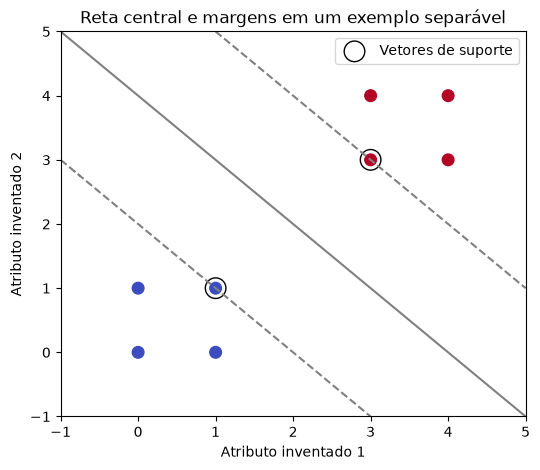

Vetores de suporte por classe no exemplo: [1 1]


In [31]:
did_X_svm = np.array([[0, 0], [0, 1], [1, 0], [1, 1],
                      [3, 3], [3, 4], [4, 3], [4, 4]], dtype=float)
did_y_svm = np.array([0, 0, 0, 0, 1, 1, 1, 1])
did_svm = SVC(kernel='linear', C=100.0)
did_svm.fit(did_X_svm, did_y_svm)
did_x1, did_x2 = np.meshgrid(np.linspace(-1, 5, 100), np.linspace(-1, 5, 100))
did_malha = np.column_stack([did_x1.ravel(), did_x2.ravel()])
did_escores = did_svm.decision_function(did_malha).reshape(did_x1.shape)
did_fig, did_ax = plt.subplots(figsize=(6, 5))
did_ax.scatter(did_X_svm[:, 0], did_X_svm[:, 1], c=did_y_svm, cmap='coolwarm', s=70)
did_ax.contour(did_x1, did_x2, did_escores, levels=[-1, 0, 1], colors='gray',
               linestyles=['--', '-', '--'])
did_ax.scatter(did_svm.support_vectors_[:, 0], did_svm.support_vectors_[:, 1],
               s=220, facecolors='none', edgecolors='black', label='Vetores de suporte')
did_ax.set(xlabel='Atributo inventado 1', ylabel='Atributo inventado 2',
           title='Reta central e margens em um exemplo separável')
did_ax.legend()
plt.show()
plt.close(did_fig)
print('Vetores de suporte por classe no exemplo:', did_svm.n_support_)

<a id="validacao"></a>
## 6. Kernels e validação: experimentar sem escolher pelo gabarito final

Se uma reta não descreve bem os dados, podemos usar um **kernel** para permitir
uma fronteira mais flexível. A ideia do kernel trick é calcular certas relações
como se estivéssemos em outro espaço de características, sem necessariamente
construir todas as novas coordenadas explicitamente.

| Nome no código | Ideia para começar |
|---|---|
| `linear` | Relações lineares no espaço de entrada |
| `poly` | Relações polinomiais, com um grau como 2 ou 3 |
| `rbf` | Similaridade que diminui com a distância; pode formar fronteiras curvas |
| `sigmoid` | Outra função de similaridade, diferente da sigmoide usada como saída da logística |

**No PDF:** páginas 42–48 apresentam SVM não linear, transformação de espaço e kernels.
O exemplo `x → (x, x²)` das páginas 43–45 ajuda a visualizar o conceito. Isso não
significa que `kernel='rbf'` esteja apenas acrescentando uma coluna x² ao nosso X.
O kernel não inventa a renda real ou obtém informações externas sobre o cliente.

Como escolher entre kernels e valores de C? Usaremos **validação cruzada** só no treino.
É como fazer pequenas provas simuladas durante o estudo e guardar a prova final para avaliação.

### 6.1 — Criar cinco dobras estratificadas

`StratifiedKFold` define como separar o conjunto de treino em partes.
Ele ainda não treina um modelo quando é criado.

- `n_splits=5`: cinco partes; a cada rodada, quatro treinam e uma valida.
- `shuffle=True`: embaralha antes de organizar as partes.
- `random_state=1`: aqui, sim, controla o embaralhamento para repetir a divisão.
- “Estratificada”: procura preservar a proporção de classes em cada parte.

Com 1.500 exemplos, cada rodada usa **1.200 para treinar e 300 para validar**.
Repetimos cinco vezes e cada exemplo participa uma vez da validação.
Essas 300 linhas vêm do treino, não são os 500 exemplos do teste separado.

`modelos_kernels = {}` guardará os modelos treinados e `resultados_kernels = []`
guardará linhas de resultados. Um dicionário facilita procurar pelo nome;
uma lista facilita juntar as linhas de uma tabela.

**No PDF:** páginas 51–54. Um cuidado de leitura: em K-fold treinamos em **k−1**
partes e validamos em uma; para k=5, são quatro partes de treino em cada rodada.

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
modelos_kernels = {}
resultados_kernels = []

**Experimento didático — olhar a divisão da primeira dobra:** `.split(X, y)`
produz índices de treino e validação. `next(...)` pega apenas a primeira rodada.
Não é uma nova separação definitiva da base: é um recorte interno do treino.

In [33]:
did_indices_treino, did_indices_validacao = next(cv.split(X_credit_treinamento, y_credit_treinamento))
print('Primeira dobra: treino =', len(did_indices_treino),
      '| validação =', len(did_indices_validacao))
print('Teste separado continua com', len(y_credit_teste), 'exemplos')

Primeira dobra: treino = 1200 | validação = 300
Teste separado continua com 500 exemplos


### 6.2 — Treinar e avaliar cada kernel

O laço percorre quatro nomes de kernel. Em cada volta:

1. Cria um SVC com o kernel escolhido e C=1.
2. `cross_val_score` treina cópias do modelo nas cinco dobras e devolve cinco notas.
   `cv=cv` reutiliza a divisão definida acima. `scoring='accuracy'` escolhe acurácia.
   `n_jobs=1` executa sem paralelizar os ajustes.
3. `notas.mean()` calcula a média das cinco notas; `notas.std()`, sua variação.
   Esse desvio entre dobras não é um intervalo de confiança.
4. `modelo.fit(...)` treina o objeto em **todo o treino**. Isso é necessário porque
   a validação cruzada ajustou cópias, não este objeto que guardaremos.
5. Guarda o modelo e adiciona um dicionário de resultados com `.append(...)`.

Também mostramos a acurácia no teste para responder ao exercício. **A escolha do
kernel será feita pela coluna de validação**, e não pelo maior valor do teste.

In [34]:
for kernel in ['linear', 'poly', 'sigmoid', 'rbf']:
    modelo = SVC(kernel=kernel, C=1.0, random_state=1)
    notas = cross_val_score(modelo, X_credit_treinamento, y_credit_treinamento,
                            cv=cv, scoring='accuracy', n_jobs=1)
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    modelos_kernels[kernel] = modelo
    resultados_kernels.append({
        'kernel': kernel, 'acuracia_cv': notas.mean(), 'desvio_cv': notas.std(),
        'acuracia_teste': accuracy_score(y_credit_teste, modelo.predict(X_credit_teste)),
    })

### 6.3 — Escolher o kernel pela média de validação

`sort_values('acuracia_cv', ascending=False)` coloca a maior média de validação em cima.
`iloc[0]` pega a primeira linha pela posição; `['kernel']` pega o nome do kernel dessa linha.

O resultado de referência escolheu **RBF**. Com C=1, as acurácias de teste foram:
linear 94,6%; polinomial 96,8%; sigmoide 83,8%; RBF 98,2%.
A coincidência de RBF vencer em validação e no teste não muda a regra:
escolhemos pela validação, para não usar o gabarito final como guia de configuração.

Mantenha os outros parâmetros em mente: “RBF foi melhor” quer dizer que venceu
**estas configurações, nesta divisão e neste critério**, não todos os SVM possíveis.

In [35]:
tabela_kernels = pd.DataFrame(resultados_kernels).sort_values('acuracia_cv', ascending=False)
display(tabela_kernels)
melhor_kernel = tabela_kernels.iloc[0]['kernel']
print('Melhor kernel pela validação cruzada:', melhor_kernel)

,kernel,acuracia_cv,desvio_cv,acuracia_teste
3,rbf,0.978000,0.007483,0.982
1,poly,0.954667,0.010456,0.968
0,linear,0.946000,0.008000,0.946
2,sigmoid,0.850667,0.018062,0.838


Melhor kernel pela validação cruzada: rbf


### 6.4 — O que muda quando aumentamos C?

O PDF, páginas 39–41, apresenta margem flexível e penalização de violações.
Pense em C como o peso do custo dessas violações:

- **C menor:** aceita mais violações em troca de maior regularização.
- **C maior:** torna as violações mais caras e pode ajustar a fronteira com mais rigor ao treino.

Uma violação de margem não precisa ser uma classificação errada: um ponto pode
estar do lado correto, mas perto demais da fronteira. C não significa quantidade
de classes, porcentagem de confiança ou número de iterações.
Aumentar C não garante melhoria no teste; pode aumentar o sobreajuste.

Na logística também existe C como força inversa de regularização. O nome parecido
expressa um controle relacionado, mas não torna os dois algoritmos a mesma coisa.

### 6.5 — Testar C=1, 10 e 100 no kernel escolhido

Criamos uma lista de resultados e um dicionário de modelos, como no teste de kernels.
`for valor_c in [1.0, 10.0, 100.0]` repete o processo para três valores de C.
O kernel permanece em `melhor_kernel` e as dobras permanecem em `cv`.

A cada volta obtemos as cinco notas, treinamos em todo o treino, guardamos o modelo
pela chave numérica `valor_c` e registramos média, desvio e teste.
É chamado ajuste manual porque escolhemos os candidatos e escrevemos o laço.
O treino e a avaliação de cada candidato continuam sendo automáticos.

In [36]:
resultados_c = []
modelos_c = {}
for valor_c in [1.0, 10.0, 100.0]:
    modelo = SVC(kernel=melhor_kernel, C=valor_c, random_state=1)
    notas = cross_val_score(modelo, X_credit_treinamento, y_credit_treinamento,
                            cv=cv, scoring='accuracy', n_jobs=1)
    modelo.fit(X_credit_treinamento, y_credit_treinamento)
    modelos_c[valor_c] = modelo
    resultados_c.append({
        'C': valor_c, 'acuracia_cv': notas.mean(), 'desvio_cv': notas.std(),
        'acuracia_teste': accuracy_score(y_credit_teste, modelo.predict(X_credit_teste)),
    })

### 6.6 — Recuperar o melhor C e seu modelo já treinado

`idxmax()` devolve o **rótulo da linha** que tem a maior média de validação.
`.loc[rotulo, 'C']` consulta o valor de C nessa linha. `float(...)` o converte em número real.
`loc` seleciona por rótulo; `iloc`, por posição. Aqui os rótulos são números,
mas eles não precisam coincidir com posições em outras tabelas.

`modelos_c[melhor_c]` recupera o modelo guardado; não o treina de novo.
Em caso de empate de médias, `idxmax` pega a primeira ocorrência. Como testamos
C em ordem crescente, isso favorece o menor dos C empatados.

Na execução de referência, C=1, 10 e 100 tiveram médias de validação de
97,80%, 98,47% e 99,07%; no teste, 98,2%, 98,8% e 99,0%.
O escolhido foi C=100. Isso é uma observação deste experimento, não uma regra
para aumentar C indefinidamente.

In [37]:
tabela_c = pd.DataFrame(resultados_c)
display(tabela_c)
melhor_c = float(tabela_c.loc[tabela_c['acuracia_cv'].idxmax(), 'C'])
svm_manual = modelos_c[melhor_c]
previsoes_manual = svm_manual.predict(X_credit_teste)
print('Ajuste manual escolhido por validação:', {'kernel': melhor_kernel, 'C': melhor_c})

,C,acuracia_cv,desvio_cv,acuracia_teste
0,1.0,0.978000,0.007483,0.982
1,10.0,0.984667,0.008589,0.988
2,100.0,0.990667,0.004422,0.990


Ajuste manual escolhido por validação: {'kernel': 'rbf', 'C': 100.0}


<a id="grade"></a>
## 7. GridSearch: organizar automaticamente uma busca de configurações

O PDF liga a escolha de kernel e C à validação na página 51. O enunciado do
trabalho pede que essa busca seja ampliada com `GridSearchCV`.
A ideia é escrever uma lista de opções, testar suas combinações e comparar as
médias de validação. Ele não conhece uma configuração ideal fora das opções fornecidas.

Novos termos:

| Opção | O que controla |
|---|---|
| `gamma` | No RBF, a escala da queda de similaridade com a distância |
| `gamma='scale'` | Calcula gamma a partir do número de atributos e da variância do treino |
| Gamma maior no RBF | Influência mais local de cada exemplo; pode tornar a fronteira mais irregular |
| `degree` | Grau do kernel polinomial |
| `coef0` | Termo constante nos kernels polinomial e sigmoide; aqui fica no padrão |

Gamma e C têm papéis diferentes: um modifica a função de similaridade; o outro
modifica a penalização das violações. Por isso podemos querer variar os dois.

### 7.1 — Escrever a grade e contar as combinações

`grade` é uma lista de três dicionários. Dentro de cada dicionário, o GridSearch
combina todas as opções das chaves. A lista permite grades diferentes por família
de kernel, evitando testar `degree` no linear, onde não teria efeito.

| Bloco | Conta | Combinações |
|---|---|---:|
| Linear | 1 kernel × 4 valores de C | 4 |
| RBF e sigmoide | 2 kernels × 4 C × 3 gamma | 24 |
| Polinomial | 1 kernel × 4 C × 3 gamma × 2 graus | 24 |
| Total | 4 + 24 + 24 | 52 |

Com cinco dobras, são **260 ajustes internos**, além do ajuste final do vencedor
em todo o treino. Isso explica por que a célula pode demorar mais que uma previsão.
As configurações do ajuste manual estão incluídas na grade.

In [38]:
grade = [
    {'kernel': ['linear'], 'C': [0.1, 1.0, 10.0, 100.0]},
    {'kernel': ['rbf', 'sigmoid'], 'C': [0.1, 1.0, 10.0, 100.0],
     'gamma': ['scale', 0.1, 1.0]},
    {'kernel': ['poly'], 'C': [0.1, 1.0, 10.0, 100.0],
     'gamma': ['scale', 0.1, 1.0], 'degree': [2, 3]},
]

### 7.2 — Configurar a busca e executar só no treino

`GridSearchCV(...)` cria o objeto de busca. `.fit(X_treino, y_treino)` começa os testes.

| Argumento | Tradução |
|---|---|
| `SVC(random_state=1)` | Modelo base do qual serão criadas as configurações |
| `param_grid=grade` | Opções que podem ser combinadas |
| `scoring='accuracy'` | Critério usado para ordenar candidatos |
| `cv=cv` | As mesmas cinco dobras estratificadas |
| `n_jobs=1` | Ajustes sem paralelização |
| `refit=True` | Treinar o vencedor novamente com todo o treino |
| `return_train_score=True` | Guardar também as notas de treino das dobras |
| `error_score='raise'` | Mostrar um erro se um ajuste falhar, em vez de ocultá-lo com uma nota especial |

Nem X de teste nem y de teste entram nesse `fit`.
Otimizamos acurácia para manter o critério da atividade, mas outro problema
poderia pedir uma métrica de seleção diferente, como recall da classe 1.

In [39]:
busca = GridSearchCV(SVC(random_state=1), param_grid=grade, scoring='accuracy',
                     cv=cv, n_jobs=1, refit=True, return_train_score=True,
                     error_score='raise')
busca.fit(X_credit_treinamento, y_credit_treinamento)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC(random_state=1)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'C': [0.1, 1.0, ...], 'kernel': ['linear']}, {'C': [0.1, 1.0, ...], 'gamma': ['scale', 0.1, ...], 'kernel': ['rbf', 'sigmoid']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_``

### 7.3 — Ler o vencedor e entender cv_results_

`cv_results_` é um dicionário de resultados de todos os candidatos.
`len(...['params'])` conta as configurações testadas.
`best_params_` informa a configuração vencedora e `best_score_`, sua média de validação.
`sort_values('rank_test_score')` coloca os melhores postos primeiro; `head(10)`
mostra dez linhas, não limita a busca a dez candidatos.

**Um nome que engana:** em `cv_results_`, `mean_test_score` é a média nas partes
de **validação das dobras**. Não é a nota nos 500 casos de teste separado.
`mean_train_score` é a média nos treinos das dobras, não necessariamente a nota
do modelo final nos 1.500 exemplos. `std_test_score` mede a variação das notas de validação.

Uma nota de treino muito maior que a de validação pode sugerir sobreajuste.
Por si só, a tabela não prova que um modelo generaliza a qualquer população.

In [40]:
print('Combinações avaliadas:', len(busca.cv_results_['params']))
print('Melhores hiperparâmetros:', busca.best_params_)
print(f'Melhor acurácia média em validação: {busca.best_score_:.4f}')
resultados_grade = pd.DataFrame(busca.cv_results_).sort_values('rank_test_score')
display(resultados_grade[['params', 'mean_train_score', 'mean_test_score',
                         'std_test_score', 'rank_test_score']].head(10))

Combinações avaliadas: 52
Melhores hiperparâmetros: {'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}
Melhor acurácia média em validação: 0.9907


,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
22,"{'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.997333,0.990667,0.004422,1
26,"{'C': 100.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.999167,0.989333,0.004899,2
20,"{'C': 10.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.996167,0.987333,0.009286,3
14,"{'C': 1.0, 'gamma': 1.0, 'kernel': 'rbf'}",0.991167,0.985333,0.009092,4
24,"{'C': 100.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.993667,0.985333,0.009092,4
16,"{'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.993000,0.984667,0.008589,6
18,"{'C': 10.0, 'gamma': 0.1, 'kernel': 'rbf'}",0.984667,0.982000,0.010456,7
10,"{'C': 1.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.985500,0.978000,0.007483,8
8,"{'C': 0.1, 'gamma': 1.0, 'kernel': 'rbf'}",0.975167,0.972000,0.010022,9
4,"{'C': 0.1, 'gamma': 'scale', 'kernel': 'rbf'}",0.962500,0.964667,0.010873,10


### 7.4 — Usar best_estimator_ e comparar com o ajuste manual

`best_estimator_` é o modelo vencedor **já ajustado** em todo o treino, por causa
de `refit=True`. Podemos chamar `predict` diretamente nele.

`comparacao_ajustes` organiza duas linhas: manual e GridSearch.
A coluna `parametros` pode guardar um dicionário dentro de uma célula da tabela.
`tabela_c['acuracia_cv'].max()` recupera a maior nota média do ajuste manual.
As notas de teste são calculadas agora para comparação descritiva.

Resultado de referência: ambos escolheram RBF com C=100 e gamma no padrão `scale`.
Empataram em validação (aproximadamente 99,07%) e no teste (99,0%).
O GridSearch não tem obrigação de superar o laço manual: se o laço já incluiu
a combinação vencedora, ele pode confirmar exatamente o mesmo resultado.

In [41]:
svm_grid = busca.best_estimator_
previsoes_grid = svm_grid.predict(X_credit_teste)
comparacao_ajustes = pd.DataFrame([
    {'ajuste': 'Manual', 'parametros': {'kernel': melhor_kernel, 'C': melhor_c},
     'acuracia_cv': tabela_c['acuracia_cv'].max(),
     'acuracia_teste': accuracy_score(y_credit_teste, previsoes_manual)},
    {'ajuste': 'GridSearch', 'parametros': busca.best_params_,
     'acuracia_cv': busca.best_score_,
     'acuracia_teste': accuracy_score(y_credit_teste, previsoes_grid)},
])
display(comparacao_ajustes)

,ajuste,parametros,acuracia_cv,acuracia_teste
0,Manual,"{'kernel': 'rbf', 'C': 100.0}",0.990667,0.99
1,GridSearch,"{'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}",0.990667,0.99


### 7.5 — Identificar empates sem tropeçar no arredondamento

A expressão `A if condicao else B` escolhe o texto a imprimir.
`1e-12` significa 0,000000000001 e evita tratar um ruído numérico minúsculo como melhoria.
`np.isclose` é outra forma de testar se dois números são praticamente iguais.
Não é um teste estatístico de igualdade de desempenhos.

Aqui a grade contém os candidatos manuais e usa a mesma validação; por isso
a melhor média da grade não deve ser inferior à manual, salvo diferenças numéricas.
Para o teste, o código identifica empate ou consulta a linha de maior acurácia
com `idxmax`. Essa consulta é uma descrição, não uma nova seleção de hiperparâmetros.

O relatório final do SVM deve mostrar a matriz `[[435, 1], [4, 60]]` na execução
de referência: 495 acertos em 500. São um falso positivo e quatro falsos negativos.

In [42]:
melhor_ajuste_cv = 'GridSearch' if busca.best_score_ > tabela_c['acuracia_cv'].max() + 1e-12 else 'Empate'
melhor_ajuste_teste = ('Empate' if np.isclose(comparacao_ajustes.iloc[0]['acuracia_teste'],
    comparacao_ajustes.iloc[1]['acuracia_teste']) else
    comparacao_ajustes.loc[comparacao_ajustes['acuracia_teste'].idxmax(), 'ajuste'])
print('Comparação por validação:', melhor_ajuste_cv)
print('Comparação descritiva no teste:', melhor_ajuste_teste)
relatorio_modelo('SVM GridSearch', previsoes_grid)

Comparação por validação: Empate
Comparação descritiva no teste: Empate
SVM GridSearch: acurácia = 0.9900 (99.00%)
Matriz [[VN, FP], [FN, VP]]:
[[435   1]
 [  4  60]]
Não pagantes encontrados: 60; não pagantes previstos como pagantes: 4.
              precision    recall  f1-score   support

    Paga (0)     0.9909    0.9977    0.9943       436
Não paga (1)     0.9836    0.9375    0.9600        64

    accuracy                         0.9900       500
   macro avg     0.9872    0.9676    0.9771       500
weighted avg     0.9900    0.9900    0.9899       500



<a id="revisao"></a>
## 8. Comparar os modelos e produzir uma explicação dos resultados

Já aprendemos a regra de cada modelo. Agora vamos reunir evidências para responder
ao trabalho: qual foi a taxa de acerto, quais tipos de erro ocorreram e como
ficou a identificação dos não pagantes.
Os próximos comandos organizam, desenham e explicam as previsões existentes.

### 8.1 — Reunir as previsões, calcular as métricas e salvar um CSV

`previsoes_finais` associa o nome do modelo às suas 500 previsões.
Não faz novo treinamento. A compreensão de lista chama `metricas_modelo` para
cada conjunto de previsões e constrói a tabela final.

`set_index('modelo')` facilita buscar uma linha pelo nome depois.
`to_csv(...)` salva a tabela em um arquivo de texto separado por vírgulas.
`encoding='utf-8-sig'` usa UTF-8 com uma marca inicial que ajuda alguns programas,
como o Excel, a reconhecer os acentos.

Neste guia, `pasta_saida` foi definida como `Parte-3/resultados_guia`, então o CSV
não substitui o arquivo da solução original.
As colunas `precisao_1`, `recall_1` e `f1_1` tratam da classe não pagante.
As outras quatro colunas são as contagens da matriz de confusão.

In [43]:
previsoes_finais = {
    'Naïve Bayes': previsoes_anteriores['Naïve Bayes'],
    'Random Forest (10)': previsoes_anteriores['Random Forest (10)'],
    'Random Forest (40)': previsoes_anteriores['Random Forest (40)'],
    'Regressão Logística': previsoes_logistica,
    'SVM manual': previsoes_manual,
    'SVM GridSearch': previsoes_grid,
}
comparacao_final = pd.DataFrame([
    metricas_modelo(nome, p) for nome, p in previsoes_finais.items()
]).set_index('modelo')
display(comparacao_final)
comparacao_final.to_csv(pasta_saida / 'comparacao_modelos_credit.csv', encoding='utf-8-sig')

,acuracia,precisao_1,recall_1,f1_1,VN,FP,FN,VP
modelo,,,,,,,,
Naïve Bayes,0.938,0.836735,0.640625,0.725664,428,8,23,41
Random Forest (10),0.968,0.928571,0.812500,0.866667,432,4,12,52
Random Forest (40),0.984,0.951613,0.921875,0.936508,433,3,5,59
Regressão Logística,0.946,0.793651,0.781250,0.787402,423,13,14,50
SVM manual,0.990,0.983607,0.937500,0.960000,435,1,4,60
SVM GridSearch,0.990,0.983607,0.937500,0.960000,435,1,4,60


### 8.2 — Desenhar, ajustar, salvar e mostrar as seis matrizes

`plt.subplots(2, 3, figsize=(15, 9))` cria uma figura com duas linhas e três
colunas de painéis. `figura` é a imagem inteira; `eixos` contém seus seis painéis.
`eixos.ravel()` transforma a organização 2×3 em uma sequência de seis eixos.

`zip(eixos.ravel(), previsoes_finais.items())` combina cada painel com um par
nome/previsões. `for eixo, (nome, previsoes) in ...` separa esses elementos em nomes.

Dentro do laço calculamos a matriz e criamos sua exibição.
`display_labels` define os nomes mostrados; `.plot(ax=eixo)` escolhe o painel;
`cmap='Blues'` usa tons de azul; `values_format='d'` mostra inteiros;
`colorbar=False` dispensa a barra de cores. Os três `set_...` dão títulos e nomes aos eixos.

Para comparar, leia **os números** de cada posição. As cores são uma ajuda visual,
não uma métrica de desempenho nem necessariamente uma escala comum entre painéis.

`tight_layout()` ajusta o espaço entre painéis para reduzir sobreposição.
`savefig` salva a figura na pasta de resultados do guia; `dpi=140` define a resolução
e `bbox_inches='tight'` reduz bordas externas.

O `if '__file__' not in globals()` faz `plt.show()` rodar no notebook, onde queremos
ver a figura logo abaixo da célula. No script, a imagem já foi salva sem abrir janela.
`plt.close(figura)` libera a figura da memória; a imagem mostrada na saída continua visível.

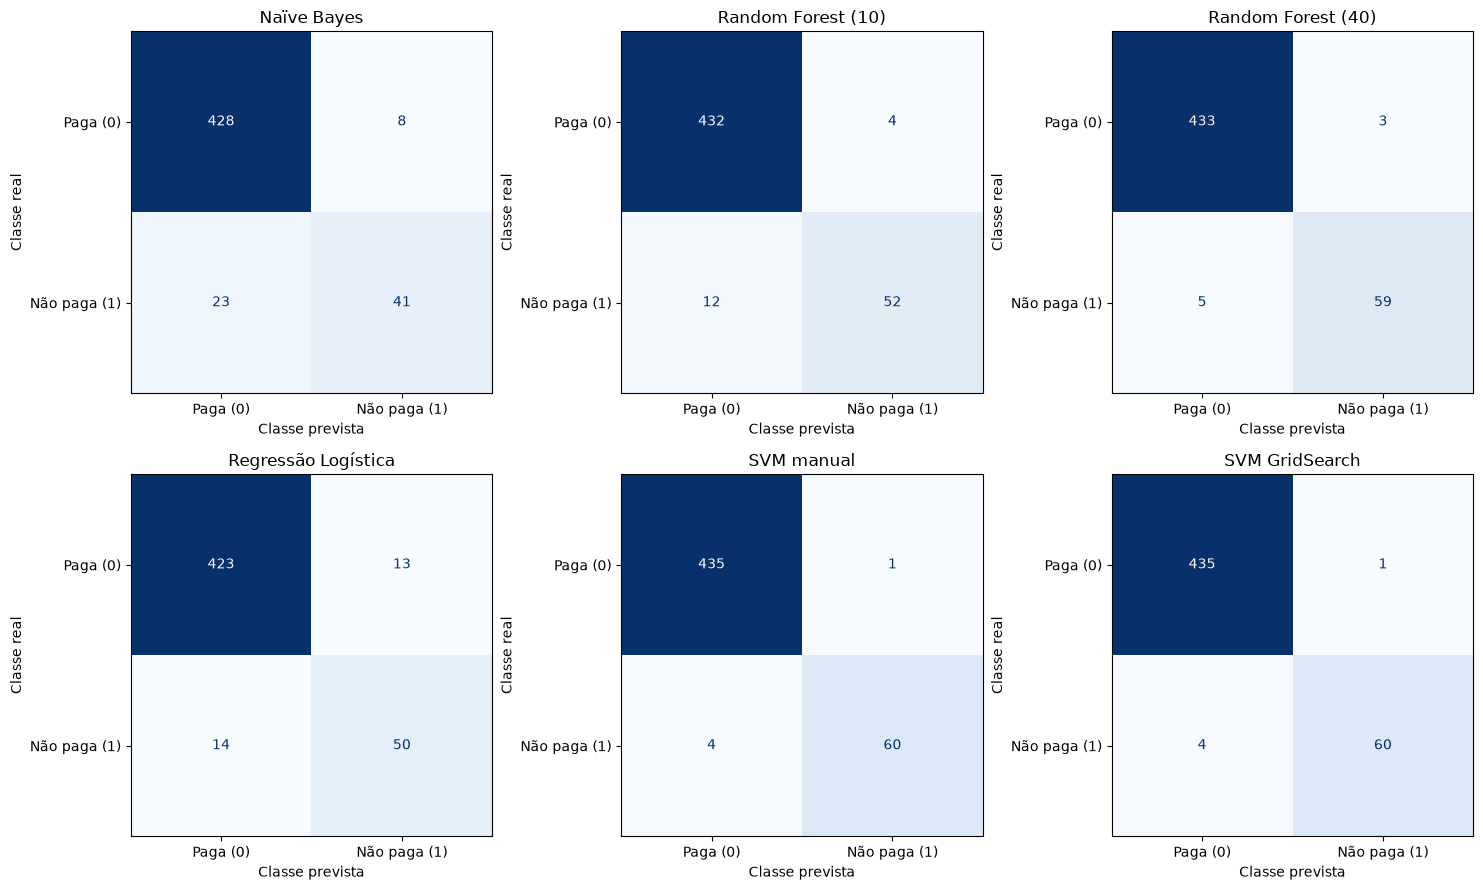

In [44]:
figura, eixos = plt.subplots(2, 3, figsize=(15, 9))
for eixo, (nome, previsoes) in zip(eixos.ravel(), previsoes_finais.items()):
    matriz = confusion_matrix(y_credit_teste, previsoes, labels=[0, 1])
    ConfusionMatrixDisplay(matriz, display_labels=['Paga (0)', 'Não paga (1)']).plot(
        ax=eixo, cmap='Blues', values_format='d', colorbar=False)
    eixo.set_title(nome)
    eixo.set_xlabel('Classe prevista')
    eixo.set_ylabel('Classe real')
figura.tight_layout()
figura.savefig(pasta_saida / 'matrizes_confusao_comparacao.png', dpi=140, bbox_inches='tight')
if '__file__' not in globals():
    plt.show()
plt.close(figura)

### 8.3 — Como ler a imagem gerada

Compare os números da mesma posição nos diferentes painéis. No canto inferior
esquerdo ficam os falsos negativos: não pagantes que o modelo classificou como pagantes.
O SVM final deixou passar quatro desses clientes; o Naïve Bayes, 23.
No canto superior direito ficam os falsos positivos. Para compreender a comparação,
olhe os dois tipos de erro e as métricas, sem decidir apenas pela cor de um quadrado.

### 8.4 — Transformar os números da logística em frases

`.loc['Regressão Logística']` pega a linha desse modelo por seu nome.
VN+VP é o total de acertos. A f-string transforma o número e a porcentagem em uma frase.

O laço compara a logística com os três resultados anteriores. A expressão
condicional escolhe “superior”, “igual” ou “inferior” pela acurácia.
Depois mostra precisão, recall e falsos negativos para que a comparação não
dependa apenas do total de acertos.

Na referência, logística versus Bayes é uma troca: o recall sobe de 64,06% para
78,12%, mas a precisão cai de 83,67% para 79,37%. Ela deixa passar menos não pagantes
(14 contra 23), mas gera mais falsos alarmes (13 contra 8).
Esse código redige a partir dos cálculos atuais, em vez de fixar as notas no texto.

In [45]:
linha_lr = comparacao_final.loc['Regressão Logística']
print(f"Parte 3, questão 7: Regressão Logística acertou {int(linha_lr['VN'] + linha_lr['VP'])}/500 "
      f"casos ({linha_lr['acuracia']:.2%}).")
for nome in ['Naïve Bayes', 'Random Forest (10)', 'Random Forest (40)']:
    linha = comparacao_final.loc[nome]
    relacao = 'superior' if linha_lr['acuracia'] > linha['acuracia'] else ('igual' if
        np.isclose(linha_lr['acuracia'], linha['acuracia']) else 'inferior')
    print(f"Parte 3, questão 8: a acurácia da logística é {relacao} à de {nome} "
          f"({linha['acuracia']:.2%}). Precisão/recall da classe 1: logística "
          f"{linha_lr['precisao_1']:.2%}/{linha_lr['recall_1']:.2%}; {nome} "
          f"{linha['precisao_1']:.2%}/{linha['recall_1']:.2%}. "
          f"Falsos negativos: {int(linha_lr['FN'])} contra {int(linha['FN'])}.")

Parte 3, questão 7: Regressão Logística acertou 473/500 casos (94.60%).
Parte 3, questão 8: a acurácia da logística é superior à de Naïve Bayes (93.80%). Precisão/recall da classe 1: logística 79.37%/78.12%; Naïve Bayes 83.67%/64.06%. Falsos negativos: 14 contra 23.
Parte 3, questão 8: a acurácia da logística é inferior à de Random Forest (10) (96.80%). Precisão/recall da classe 1: logística 79.37%/78.12%; Random Forest (10) 92.86%/81.25%. Falsos negativos: 14 contra 12.
Parte 3, questão 8: a acurácia da logística é inferior à de Random Forest (40) (98.40%). Precisão/recall da classe 1: logística 79.37%/78.12%; Random Forest (40) 95.16%/92.19%. Falsos negativos: 14 contra 5.


### 8.5 — Escrever o resultado de kernel, C e GridSearch

`tabela_c.iterrows()` percorre os pares índice/linha de uma tabela.
Em `for _, linha in ...`, o nome `_` indica que não precisamos usar o índice recebido;
ele continua sendo uma variável Python, apenas seguimos uma convenção de leitura.

`:.2%` apresenta porcentagens; `:g` mostra C de forma compacta, por exemplo 100
em vez de 100.0. Os prints seguintes mostram os hiperparâmetros escolhidos e o empate.
São a redação dos resultados, não uma etapa adicional de otimização.

In [46]:
print(f'Parte 4, questão 4: melhor kernel pela validação cruzada = {melhor_kernel}.')
for _, linha in tabela_c.iterrows():
    print(f"Parte 4, questão 5: C={linha['C']:g}: validação {linha['acuracia_cv']:.2%}, "
          f"teste {linha['acuracia_teste']:.2%}.")
print('Parte 4, questão 6: melhor combinação da grade:', busca.best_params_)
print('Ajuste manual versus GridSearch: validação =', melhor_ajuste_cv,
      '| teste =', melhor_ajuste_teste)

Parte 4, questão 4: melhor kernel pela validação cruzada = rbf.
Parte 4, questão 5: C=1: validação 97.80%, teste 98.20%.
Parte 4, questão 5: C=10: validação 98.47%, teste 98.80%.
Parte 4, questão 5: C=100: validação 99.07%, teste 99.00%.
Parte 4, questão 6: melhor combinação da grade: {'C': 100.0, 'gamma': 'scale', 'kernel': 'rbf'}
Ajuste manual versus GridSearch: validação = Empate | teste = Empate


### 8.6 — Comparar o SVM com os demais sem esconder os erros

O último laço recupera a linha do SVM GridSearch e a compara com cada modelo anterior.
O `if` decide apenas a descrição de acurácia; as frases mostram também precisão,
recall e falsos negativos da classe 1.

O SVM ajustado teve 99,0%, contra 98,4% da floresta de 40 árvores: **três acertos
a mais em 500 exemplos**. O recall dos não pagantes subiu de 59/64 para 60/64;
os falsos positivos caíram de três para um.
São resultados favoráveis neste teste, mas uma diferença pequena não prova
superioridade universal nem significância estatística.

In [47]:
linha_svm = comparacao_final.loc['SVM GridSearch']
for nome in ['Naïve Bayes', 'Random Forest (10)', 'Random Forest (40)', 'Regressão Logística']:
    linha = comparacao_final.loc[nome]
    relacao = 'superior' if linha_svm['acuracia'] > linha['acuracia'] else ('igual' if
        np.isclose(linha_svm['acuracia'], linha['acuracia']) else 'inferior')
    print(f"Comparação final: a acurácia do SVM GridSearch ({linha_svm['acuracia']:.2%}) "
          f"é {relacao} à de {nome} ({linha['acuracia']:.2%}). "
          f"Precisão/recall da classe 1: SVM {linha_svm['precisao_1']:.2%}/{linha_svm['recall_1']:.2%}; "
          f"{nome} {linha['precisao_1']:.2%}/{linha['recall_1']:.2%}. "
          f"Falsos negativos: {int(linha_svm['FN'])} contra {int(linha['FN'])}.")

Comparação final: a acurácia do SVM GridSearch (99.00%) é superior à de Naïve Bayes (93.80%). Precisão/recall da classe 1: SVM 98.36%/93.75%; Naïve Bayes 83.67%/64.06%. Falsos negativos: 4 contra 23.
Comparação final: a acurácia do SVM GridSearch (99.00%) é superior à de Random Forest (10) (96.80%). Precisão/recall da classe 1: SVM 98.36%/93.75%; Random Forest (10) 92.86%/81.25%. Falsos negativos: 4 contra 12.
Comparação final: a acurácia do SVM GridSearch (99.00%) é superior à de Random Forest (40) (98.40%). Precisão/recall da classe 1: SVM 98.36%/93.75%; Random Forest (40) 95.16%/92.19%. Falsos negativos: 4 contra 5.
Comparação final: a acurácia do SVM GridSearch (99.00%) é superior à de Regressão Logística (94.60%). Precisão/recall da classe 1: SVM 98.36%/93.75%; Regressão Logística 79.37%/78.12%. Falsos negativos: 4 contra 14.


## 9. O que você deve conseguir explicar depois desta leitura

O roteiro abaixo acompanha o fluxo do programa inteiro:

1. **Carregar:** recuperar as tabelas e seus gabaritos dos arquivos anteriores.
2. **Representar:** manter os códigos das categorias e retirar `moderado` só no exercício pequeno.
3. **Aprender:** executar `fit` para descobrir os parâmetros do modelo.
4. **Prever:** executar `predict` nas entradas sem fornecer o gabarito ao modelo.
5. **Medir:** comparar previsões com y de teste, olhando os quatro tipos de contagem.
6. **Escolher configurações:** usar validação interna ao treino para kernel, C e gamma.
7. **Comunicar:** mostrar tabelas, gráficos e uma análise que indique o tipo de erro.

### Perguntas rápidas, com resposta para conferir

**1. Por que a regressão logística é usada numa atividade de classificação?**

Porque estima uma probabilidade de classe e a utiliza para devolver uma categoria.
O nome do algoritmo não muda o objetivo desta tarefa.

**2. `fit` e `predict` fazem a mesma coisa?**

Não. `fit` aprende parâmetros com exemplos e respostas; `predict` aplica a regra
aprendida a entradas. Rodar `predict` não ensina os rótulos do teste ao modelo.

**3. Probabilidade 0,72 significa 72% de risco alto?**

Depende de qual classe aquela coluna representa. Para o modelo pequeno,
a segunda coluna é a probabilidade de `baixo`; consulte sempre `classes_` e o Encoder.

**4. Uma acurácia de 87,2% já mostra que identificamos não pagantes?**

Não. Como 436 de 500 pagam, prever sempre “paga” alcança esse valor e encontra
zero não pagantes. O recall da classe 1 revela essa falha.

**5. Quem define B0 e os coeficientes? E quem define C?**

O treino descobre os primeiros. Nós definimos candidatos de C, ou uma busca
compara esses candidatos. C é hiperparâmetro; os coeficientes são parâmetros aprendidos.

**6. C maior sempre é melhor?**

Não. Ele modifica o equilíbrio do ajuste e pode piorar a generalização.
Comparamos candidatos por validação para observar o que acontece nesta base.

**7. `mean_test_score` do GridSearch é o resultado dos 500 casos finais?**

Não. É a média nas validações internas das dobras. A nota do teste separado
é calculada depois por `accuracy_score(y_credit_teste, previsoes_grid)`.

**8. Por que GridSearch empatou com o ajuste manual?**

Porque ambos incluíram a configuração vencedora. A busca automática organizou
mais combinações, mas não encontrou uma média melhor entre elas.

### Pequenos exercícios para fixar sem alterar a solução

- Pegue o segundo cliente e repita a soma B0 + entradas × pesos, usando uma variável nova.
  A probabilidade de `baixo` deve ficar perto de 8,8%, levando à classe `alto`.
- Confira a precisão do SVM final: 60/(60+1), e seu recall: 60/(60+4).
- Explique com palavras a diferença entre um FP e um FN na Credit Data.
- Antes de executar, tente prever o resultado de `len(grade)` e explique por que
  ele é 3, apesar de a busca testar 52 combinações: a lista tem três **blocos de opções**.

## 10. Limites e cuidados para interpretar a atividade

A base pequena usa só 11 exemplos e não tem teste separado. Suas duas previsões
servem para demonstrar o funcionamento, não para medir generalização com confiança.
As probabilidades desse modelo também não devem ser tomadas como garantias reais.

Na base maior, a busca usa apenas o treino, mas o teste aparece em muitas comparações
e já foi consultado nas etapas anteriores. Isso cumpre a atividade, porém não constitui
uma avaliação final independente de todas as escolhas. Em outro estudo, seria
necessário reservar dados novos ou estruturar validação aninhada para avaliar o processo.

O código de preparação original de `credit.pkl` não está disponível, portanto
a separação correta da padronização não pode ser auditada a partir deste trabalho.
Também não demonstramos significância estatística das diferenças entre modelos.

**Você não precisa decorar o script.** A parte principal é conseguir dizer
o que entra no modelo, o que ele aprende, o que sai dele e como conferimos se a saída é útil.

## Mapa entre o PDF e o código

| Páginas do PDF | Conceito do material | Onde aparece no código |
|---|---|---|
| 6–8 | Aprendizado supervisionado e classificação | Separação entre X e y; `fit(X, y)` |
| 9–15 | Probabilidade, sigmoide e equação linear | `LogisticRegression`, `intercept_`, `coef_` e experimento da sigmoide |
| 16 e 23 | Encoder e classes alto/baixo | `LabelEncoder`, máscara de exclusão de `moderado` |
| 17–18 | Aprender pesos minimizando custo | `fit`; aqui o solver é L-BFGS |
| 19–22 | Probabilidade e limiar de classificação | `predict_proba`, `predict` e cálculo manual de z |
| 30–34 | Hiperplano e margem | `SVC(kernel='linear')` e desenho didático |
| 35–36 | Vetores de suporte | `support_vectors_` no desenho didático |
| 39–41 | Margem flexível e penalização | Variação de `C` |
| 42–48 | SVM não linear e kernels | `kernel='poly'`, `'sigmoid'` e `'rbf'`; papel de gamma |
| 49–50 | Extensões para múltiplas classes | Contexto: aqui o exercício usa duas classes, sem implementação manual multiclasse |
| 51–54 | Escolha de configurações e validação | Holdout de `credit.pkl`, `StratifiedKFold`, `cross_val_score`, `GridSearchCV` |

As métricas e o GridSearch complementam os conceitos do PDF para responder ao
enunciado do projeto. As páginas 58–59 tratam de SVR e encerramento; **SVR**
prevê valores contínuos e não é o algoritmo usado neste exercício de classificação.

**Referências de implementação:** documentação das classes instaladas em `sklearn`
e [notebook resolvido do projeto](TRABALHO_3_PARTE_3_Regressao_Logistica_SVM_RESOLVIDO.ipynb).
As descrições dos argumentos foram conferidas no scikit-learn 1.9.1 usado neste ambiente.